# Rule lift by stage
Which rules change their lift between stages: a clustered heatmap of every rule's log2 lift per FOV (or patient), and a volcano plot of the rules whose lift differs between Control and Severe.

## Setup

In [1]:
from pathlib import Path
import sys

from IPython.display import display

ROOT = next(
    folder for folder in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (folder / "result_summary" / "data_helper.py").exists()
)
sys.path[:0] = [
    str(ROOT / "result_summary"),
    str(ROOT / "result_summary" / "differential_rules" / "scripts"),
]

import data_helper as dh
import differential_stats as ds
import differential_vis as dv
import rule_metrics as rm

### Shared settings

In [2]:
ORGANS = ("Colon", "Duodenum")  # one plot per organ
SCORE = "Pathological score"    # Clinical score / Pathological score
LEVEL = "FOV"               # FOV / patient
KIND = None                     # None (attracts and avoids) / rm.ATTRACTS / rm.AVOIDS
MIN_LIFT = 0.1                  # a lower lift is raised to this before log2, since log2(0) has no value

### Heatmap settings

In [3]:
MIN_FOV = 0.0   # keep rules found in more than this share of the FOVs
CLIP = 2.0      # colours stop at this log2 lift, either way
FLIP = False    # True: FOVs (or patients) as rows, rules as columns

### Volcano settings

In [4]:
GROUPS = ("Control", "Severe")             # compared groups: the gap is the second minus the first
MIN_TESTABLE = {"FOV": 10, "patient": 3}  # testable units a rule needs in each group
MIN_SHARE = 0.1                           # share of its testable units a rule must be found in
MAX_FDR = 0.05
MIN_EFFECT = None                         # smallest gap in mean log2 lift to count, either way; None for no minimum
N_PERMUTATIONS = 5_000
N_NAMES = 5                               # rules named on the plot
CLOSE_UP = 4                              # close-ups: this many biggest gaps that do not pass, or a list of rule names

## Data

In [5]:
df_cells, df_fovs, rules = ds.load_rules()

Dropped 21 FOVs: Control_S
Loaded 598093 cells; FOVs: 267, biopsies: 73, patients: 71
Read results_CN_pairwise.csv
Loaded 15660 rules.
Kept 6978 rules at FDR <= 0.05.
Kept 6946 rules naming no Unidentified.
Kept 6946 rules (max_items=2, kind=None).


## Logic

In [6]:
def lift_by_unit(organ):
    """`organ`'s rule x unit log2 lift at LEVEL (a patient takes the mean of its FOVs), the SCORE group of each unit,
    and the kind of each rule."""
    fovs = df_fovs[df_fovs["Organ"].eq(organ)]
    table = ds.lift_table(rules, df_cells, fovs["FOV"], KIND, MIN_LIFT)
    table, groups = (ds.per_patient(table, fovs, SCORE, "mean") if LEVEL == "patient"
                     else (table, fovs.set_index("FOV")[SCORE]))
    return table, groups, ds.rule_kinds(rules[rules["FOV"].isin(fovs["FOV"])], KIND)


def heatmap_table(organ):
    """`organ`'s lift table with the rules found in more than MIN_FOV of its FOVs."""
    table = lifts[organ][0]
    fovs = df_fovs.loc[df_fovs["Organ"].eq(organ), "FOV"]
    return table[table.index.isin(dh.frequent_rules(rules[rules["FOV"].isin(fovs)], MIN_FOV))]


def close_up_rules(result):
    """The CLOSE_UP biggest gaps among the rules that do not pass, or the rules CLOSE_UP names."""
    if not isinstance(CLOSE_UP, int):
        return CLOSE_UP
    missed = result[~ds.passing(result, MAX_FDR, MIN_EFFECT)]
    return missed["gap"].abs().nlargest(CLOSE_UP).index


def differences(organ):
    """`organ`'s volcano, the close-ups of its biggest gaps that do not pass, and the table of the rules that pass."""
    (table, groups, kinds), result = lifts[organ], gaps[organ]
    dv.plot_volcano(result, kinds, *GROUPS, MAX_FDR, MIN_EFFECT, N_NAMES, UNIT, scope(organ), save=name("volcano", organ))
    if result is not None:
        dv.plot_close_ups(table, groups, result, kinds, close_up_rules(result), *GROUPS, MAX_FDR, MIN_EFFECT, UNIT,
                          scope(organ), save=name("close_ups", organ))
        display(result[ds.passing(result, MAX_FDR, MIN_EFFECT)])


def name(plot, organ):
    """File name of `plot` for `organ` with the settings it was built with."""
    return f"{plot}_{organ}_{SCORE}_{LEVEL}_{KIND or 'both'}".lower().replace(" ", "_")


def scope(organ):
    """The settings line under a plot of `organ`."""
    return f"{organ} · {SCORE} · per {LEVEL} · {KIND or 'attracts and avoids'}"


UNIT = "FOVs" if LEVEL == "FOV" else "patients"

## Lift table

In [7]:
lifts = {organ: lift_by_unit(organ) for organ in ORGANS}
{organ: table.shape for organ, (table, _, _) in lifts.items()}

{'Colon': (207, 97), 'Duodenum': (315, 170)}

## Heatmap

c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\differential_rules\summary_downloads\lift_heatmap_colon_pathological_score_fov_both.pdf


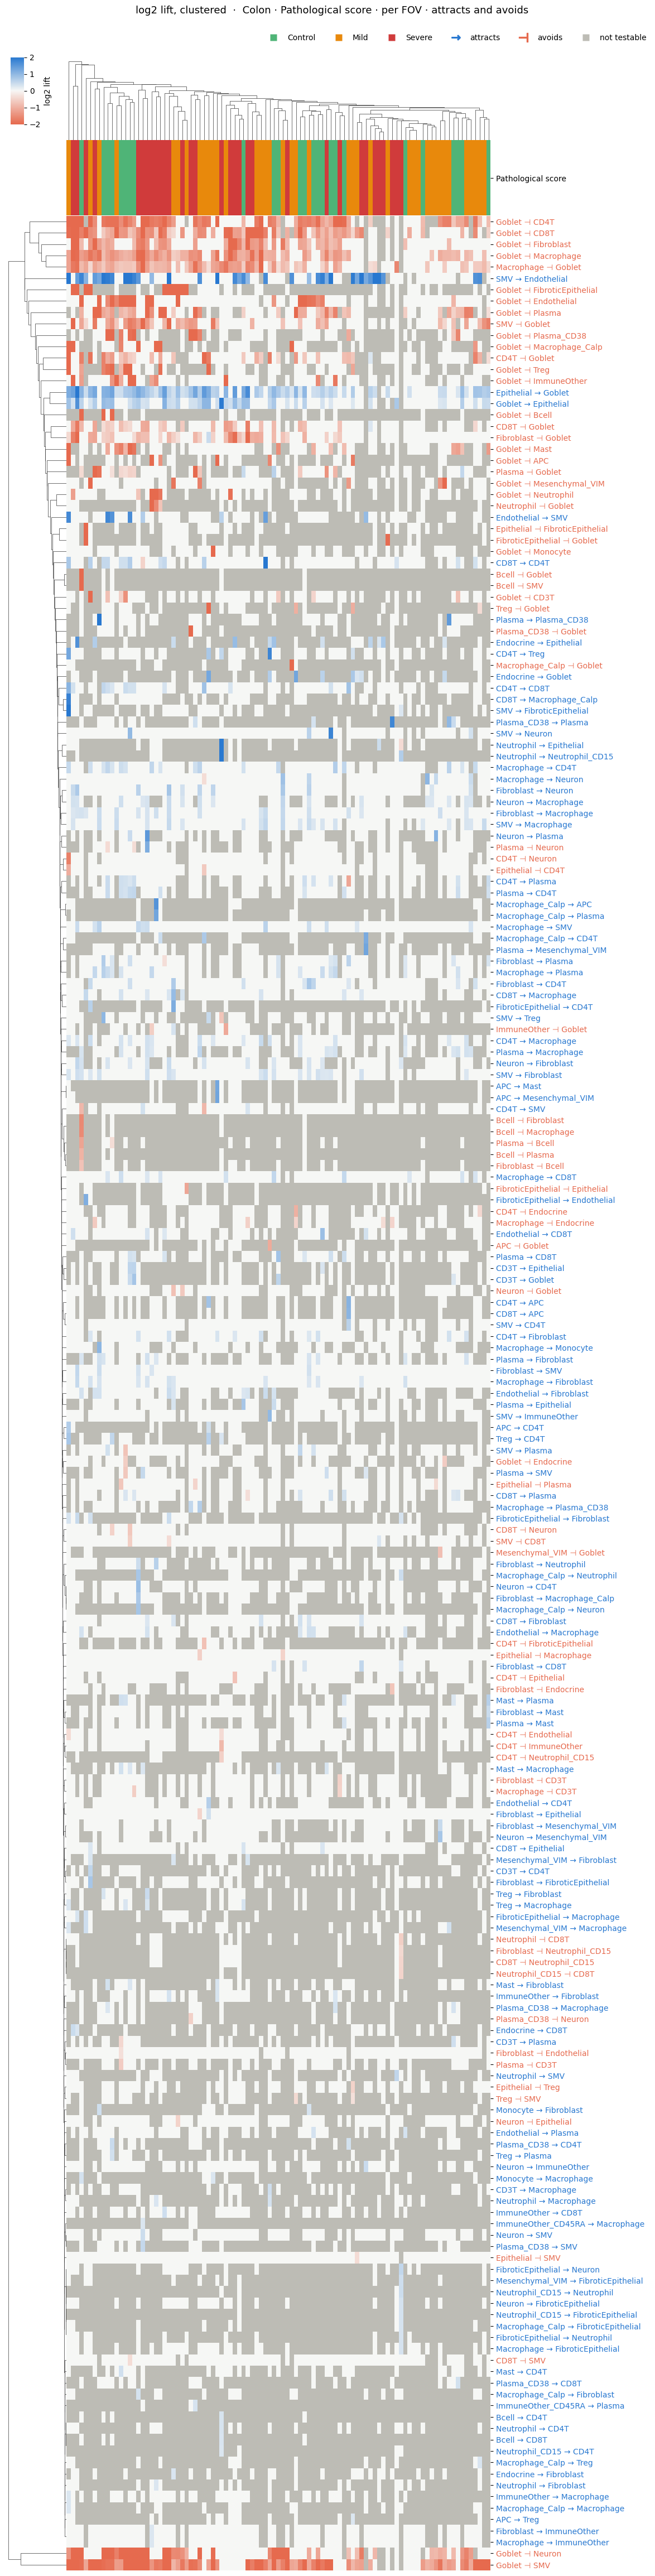

c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
c:\Users\Owner\Documents\script-rule-mining\venv\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\differential_rules\summary_downloads\lift_heatmap_duodenum_pathological_score_fov_both.pdf


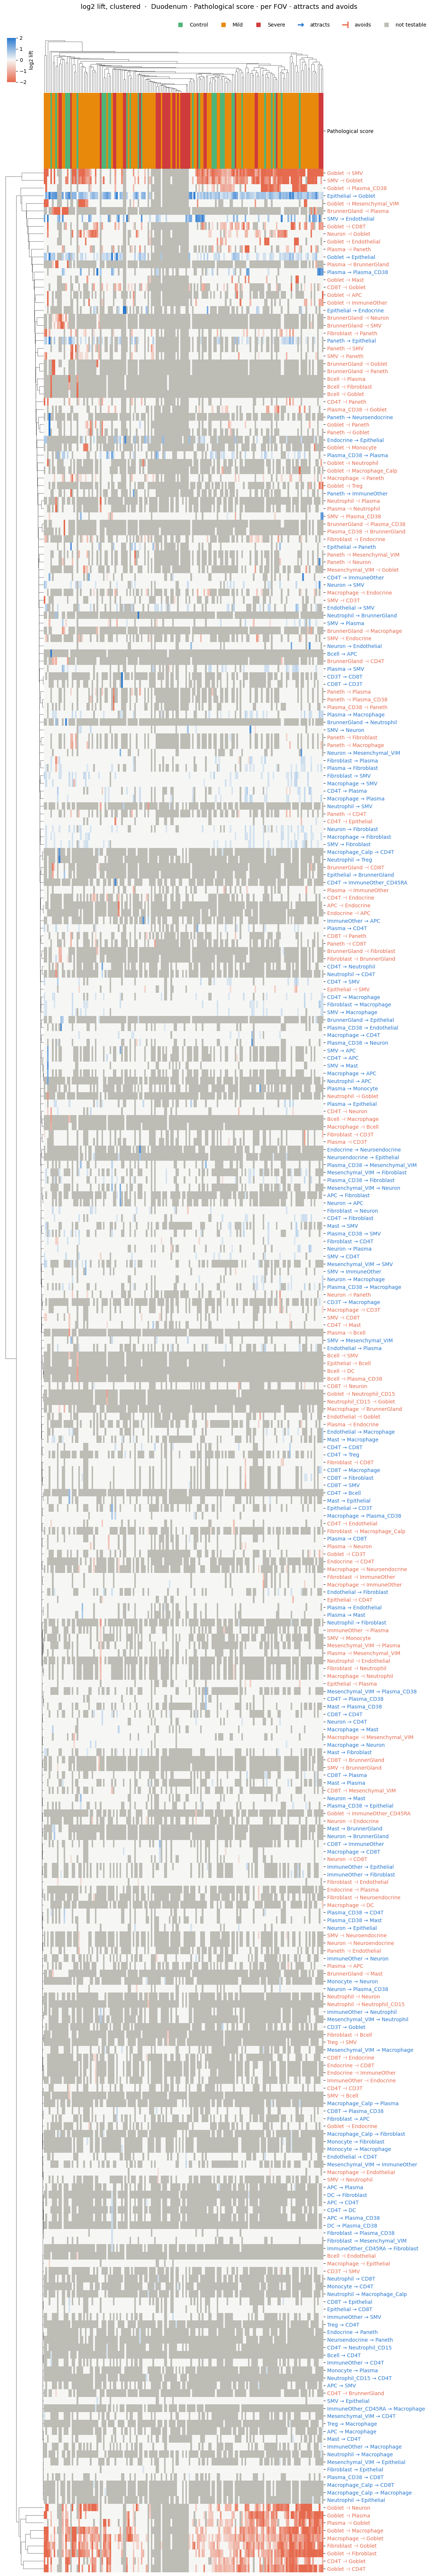

In [8]:
for organ, (_, groups, kinds) in lifts.items():
    dv.plot_lift_heatmap(heatmap_table(organ), groups, kinds, CLIP, FLIP, scope(organ), save=name("lift_heatmap", organ))

## Volcano
**How the test works.** For each rule we take its mean log2 lift in each group, using only the units (FOVs or patients) where the rule can be tested. We then shuffle the group labels many times (N_PERMUTATIONS) and count how often a random split gives a gap at least as big as the real one: that share is the p-value. As many rules are tested at once, the p-values are corrected for it (Benjamini-Hochberg FDR). A rule is tested only when each group has MIN_TESTABLE testable units and the rule is found in MIN_SHARE of them.

Per organ: the volcano, then close-ups of the biggest gaps that did not pass (a big gap with few testable units, or one extreme unit, is not sure), then the rules that pass.

In [9]:
gaps = {organ: ds.gaps(table, groups, *GROUPS, MIN_TESTABLE[LEVEL], MIN_SHARE, N_PERMUTATIONS)
        for organ, (table, groups, _) in lifts.items()}

### Per organ

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\differential_rules\summary_downloads\volcano_colon_pathological_score_fov_both.pdf


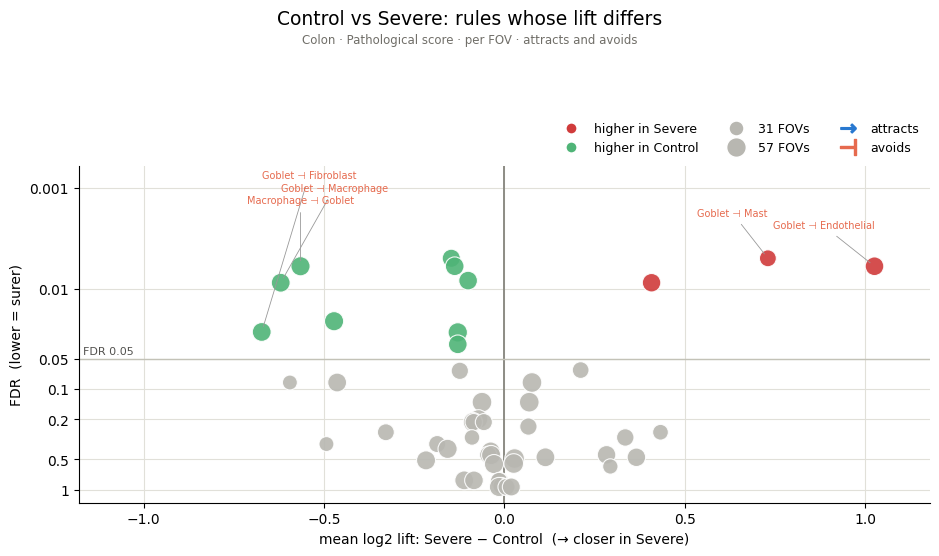

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\differential_rules\summary_downloads\close_ups_colon_pathological_score_fov_both.pdf


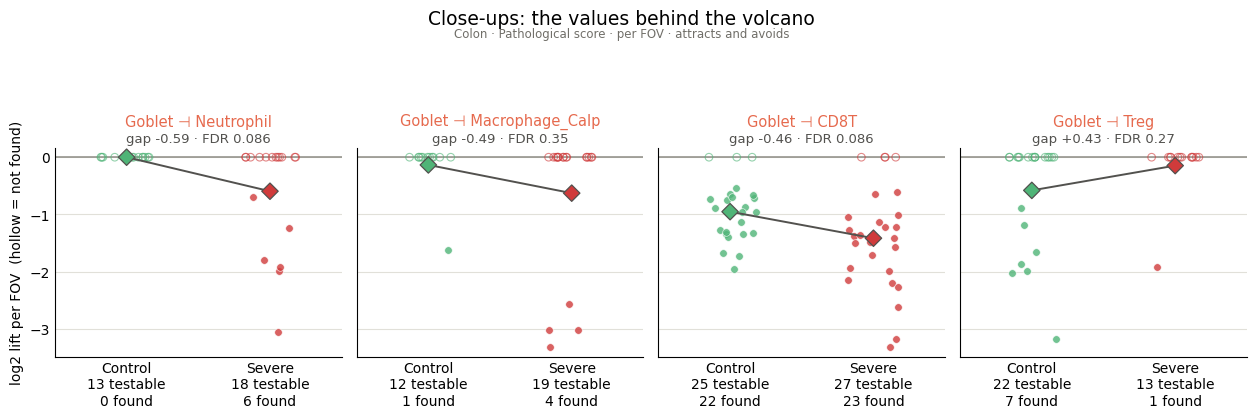

,mean Control,mean Severe,gap,n Control,n Severe,p,fdr
Clean_Rule,,,,,,,
CD4T -> Plasma,0.147202,0.000000,-0.147202,25,23,0.000200,0.004999
Goblet -> Mast,-0.730517,0.000000,0.730517,22,19,0.000200,0.004999
Goblet -> Endothelial,-1.188699,-0.162619,1.026080,25,26,0.000400,0.005999
Fibroblast -> Plasma,0.124133,-0.013649,-0.137782,25,26,0.000600,0.005999
Macrophage -> Goblet,-0.531169,-1.096425,-0.565256,25,29,0.000600,0.005999
CD8T -> Plasma,0.087251,-0.013317,-0.100569,25,26,0.001000,0.008332
CD4T -> Goblet,-0.485376,-0.077324,0.408052,25,25,0.001400,0.008748
Goblet -> Macrophage,-0.723295,-1.343429,-0.620135,25,27,0.001400,0.008748
Fibroblast -> Goblet,-0.202734,-0.674956,-0.472221,25,29,0.003799,0.021107


saved C:\Users\Owner\Documents\script-rule-mining\result_summary\differential_rules\summary_downloads\volcano_duodenum_pathological_score_fov_both.pdf


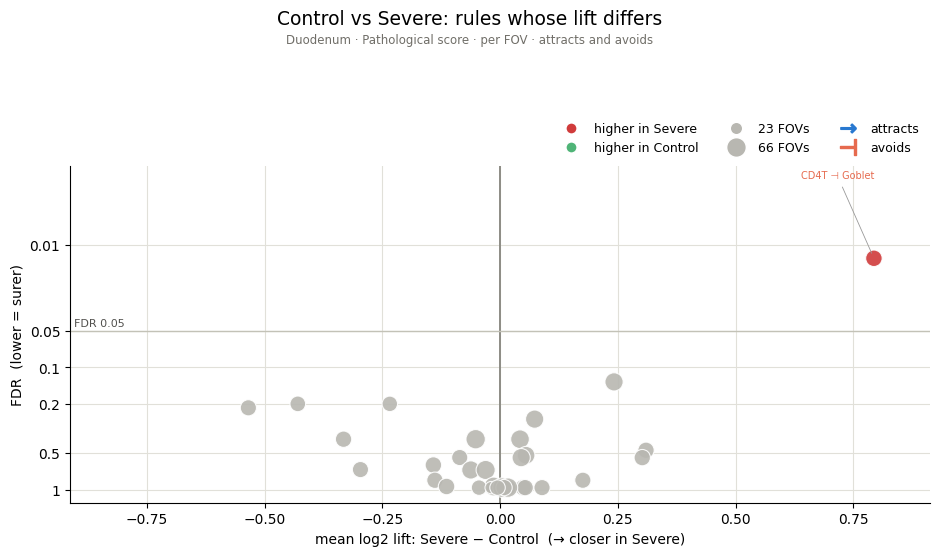

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\differential_rules\summary_downloads\close_ups_duodenum_pathological_score_fov_both.pdf


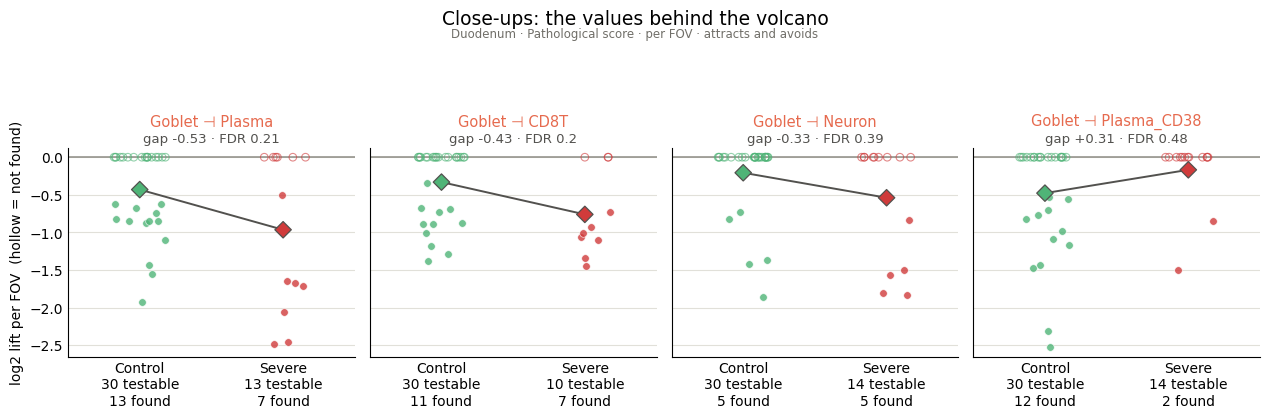

,mean Control,mean Severe,gap,n Control,n Severe,p,fdr
Clean_Rule,,,,,,,
CD4T -> Goblet,-0.940391,-0.146518,0.793873,31,14,0.0004,0.012797


In [10]:
for organ in ORGANS:
    differences(organ)